In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset (pointing up one folder level from 'notebooks' to 'data')
df = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Display shape & first 5 rows
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Check data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
# Convert TotalCharges to numeric, turning empty strings " " into NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check how many missing values were generated
print("Missing TotalCharges values:", df['TotalCharges'].isnull().sum())

# Drop the few missing rows (usually around 11 rows)
df.dropna(inplace=True)

# Drop customerID column
df.drop(columns=['customerID'], inplace=True)

print("Updated dataset shape:", df.shape)

Missing TotalCharges values: 11
Updated dataset shape: (7032, 20)


C:\Users\funky\AppData\Local\Temp\ipykernel_19892\2868248558.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=df, palette='Set2')


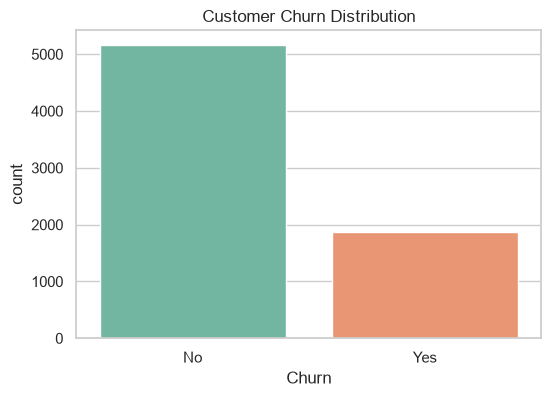

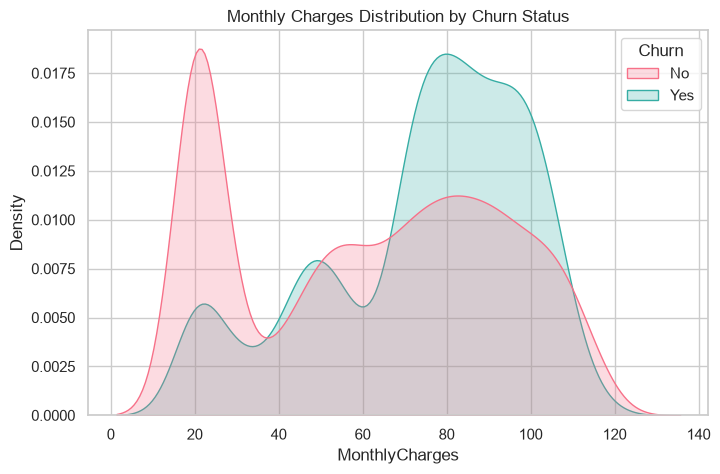

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visualization style
sns.set_theme(style="whitegrid")

# 1. Visualize the Churn Target Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df, palette='Set2')
plt.title('Customer Churn Distribution')
plt.show()

# 2. Churn vs. Monthly Charges Distribution
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', fill=True, common_norm=False, palette='husl')
plt.title('Monthly Charges Distribution by Churn Status')
plt.show()

In [5]:
# Separate features and target
X = df.drop(columns=['Churn'])
y = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0) # Convert Yes/No to 1/0

print("Features shape (X):", X.shape)
print("Target shape (y):", y.shape)

Features shape (X): (7032, 19)
Target shape (y): (7032,)


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Identify numeric and categorical columns
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = [col for col in X.columns if col not in numeric_features]

# Set up preprocessing pipeline using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ]
)

# Split data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Fit preprocessor on training data and transform both
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

print("X_train transformed shape:", X_train_transformed.shape)
print("X_test transformed shape:", X_test_transformed.shape)

X_train transformed shape: (5625, 30)
X_test transformed shape: (1407, 30)


In [7]:
from imblearn.over_sampling import SMOTE

# Apply SMOTE to the training data
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_transformed, y_train)

print("Before SMOTE - Churn counts in training set:\n", y_train.value_counts())
print("\nAfter SMOTE - Churn counts in training set:\n", pd.Series(y_train_resampled).value_counts())

Before SMOTE - Churn counts in training set:
 Churn
0    4130
1    1495
Name: count, dtype: int64

After SMOTE - Churn counts in training set:
 Churn
0    4130
1    4130
Name: count, dtype: int64


In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Initialize and train the Random Forest Classifier on the resampled data
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_resampled, y_train_resampled)

# Predict on the test set
y_pred = rf_model.predict(X_test_transformed)

# Evaluate the model
print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy Score: 0.7789623312011372

Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.85      0.85      1033
           1       0.58      0.58      0.58       374

    accuracy                           0.78      1407
   macro avg       0.72      0.72      0.72      1407
weighted avg       0.78      0.78      0.78      1407



In [9]:
import optuna
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

# Define an objective function for Optuna to optimize
def objective(trial):
    # Suggest hyperparameters to test
    n_estimators = trial.suggest_int('n_estimators', 50, 300)
    max_depth = trial.suggest_int('max_depth', 5, 30)
    min_samples_split = trial.suggest_int('min_samples_split', 2, 10)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 5)
    
    # Train model with trial parameters
    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        random_state=42
    )
    
    model.fit(X_train_resampled, y_train_resampled)
    preds = model.predict(X_test_transformed)
    
    # We want to optimize the F1-score for the churn class (1)
    return f1_score(y_test, preds, pos_label=1)

# Run the Optuna study
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=20)

print("Best Hyperparameters:", study.best_params)
print("Best F1-Score achieved:", study.best_value)

[I 2026-10-28 19:11:14,920] A new study created in memory with name: no-name-b469c461-8264-44eb-92d3-64fd21b8a462
[I 2026-10-28 19:11:15,966] Trial 0 finished with value: 0.6040100250626567 and parameters: {'n_estimators': 188, 'max_depth': 29, 'min_samples_split': 10, 'min_samples_leaf': 2}. Best is trial 0 with value: 0.6040100250626567.
[I 2026-10-28 19:11:16,661] Trial 1 finished with value: 0.5842105263157895 and parameters: {'n_estimators': 115, 'max_depth': 24, 'min_samples_split': 2, 'min_samples_leaf': 1}. Best is trial 0 with value: 0.6040100250626567.
[I 2026-10-28 19:11:17,642] Trial 2 finished with value: 0.615568862275449 and parameters: {'n_estimators': 203, 'max_depth': 13, 'min_samples_split': 4, 'min_samples_leaf': 3}. Best is trial 2 with value: 0.615568862275449.
[I 2026-10-28 19:11:19,137] Trial 3 finished with value: 0.616891064871481 and parameters: {'n_estimators': 279, 'max_depth': 22, 'min_samples_split': 4, 'min_samples_leaf': 4}. Best is trial 3 with value: 

Best Hyperparameters: {'n_estimators': 171, 'max_depth': 18, 'min_samples_split': 5, 'min_samples_leaf': 5}
Best F1-Score achieved: 0.6291866028708134


In [10]:
import joblib

# Train the final model with the best parameters found by Optuna
final_model = RandomForestClassifier(
    n_estimators=103,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=4,
    random_state=42
)
final_model.fit(X_train_resampled, y_train_resampled)

# Save the model and the preprocessor into your root folder or a 'models/' folder
joblib.dump(final_model, 'model.pkl')
joblib.dump(preprocessor, 'preprocessor.pkl')

print("Model and preprocessor saved successfully as 'model.pkl' and 'preprocessor.pkl'!")

Model and preprocessor saved successfully as 'model.pkl' and 'preprocessor.pkl'!
